# 01 · Historical diagonal: the batch-gradient-square statistic

A standalone tutorial using the maintained `laplace_hypopinn` package. [Tutorial index](README.md) · [Method definitions](../../docs/methods.md)

## Goal

Learn the full path from synthetic receiver observations to a trained travel-time field, a local parameter distribution, and sampled source locations. The figures and checks below are generated by the displayed code.

This notebook follows the maintained `legacy_diagonal` compatibility path on the analytic velocity-gradient problem. For each independently resampled curvature batch, it differentiates the **sum of the mean PDE, receiver and positivity losses**, squares that total gradient elementwise, and accumulates
$$
f_j=\sum_{b=1}^{B}n_b[\partial_j\mathcal L^{(b)}_{\mathrm{mean}}]^2,
\qquad P_{jj}=\texttt{add}+\texttt{multiply}\,f_j.
$$
Sampling uses independent parameter perturbations with standard deviations $P_{jj}^{-1/2}$ around the same saved trained center. Squaring a summed gradient includes cross-residual and cross-family effects: $f$ is neither the diagonal GGN nor a per-observation Fisher nor an exact Hessian. Its dependence on the number and size of resampled batches is part of the historical convention.

The tutorial keeps `add=1000` and `multiply=0.001`, but reduces batch, training and sampling counts to teaching budgets. Training uses `prior_precision=0`; `add` therefore acts as post-hoc damping, not a matched training prior. The fixed residual plan built in step 3 is used by the corrected methods; this method intentionally draws fresh batches from `problem` with replacement. Native parameter units in the diagnostic are not travel-time or spatial units.


## Setup

From the repository root, install `python -m pip install -e ".[notebooks]" jupyterlab`, then register/select that environment’s kernel with `python -m ipykernel install --sys-prefix --name laplace-hypopinn`. Open this notebook in JupyterLab or an editor and **Restart Kernel → Run All**. No downloads, GPU, external dataset, or previous tutorial outputs are required.

This synthetic example uses `(z, x)` coordinates in **km**, velocity in **km/s**, and travel time in **s**.

In [1]:
%matplotlib inline
from dataclasses import replace
import importlib.metadata
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from laplace_hypopinn.config import LaplaceConfig, resolve_dtype
from laplace_hypopinn.curvature.residuals import make_residual_plan
from laplace_hypopinn.data import prepare_problem, sample_training_batch
from laplace_hypopinn.losses import loss_terms
from laplace_hypopinn.model import flatten_parameters, initialize_model, make_mlp_forward
from laplace_hypopinn.prediction import grid_location, predict_grid, sample_locations
from laplace_hypopinn.presets import load_preset
from laplace_hypopinn.training import train
from laplace_hypopinn.types import RandomStreams

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})
colors = {"map": "#0072B2", "truth": "#222222", "posterior": "#56B4E9",
          "receiver": "#E69F00"}

def as_numpy(tensor):
    return tensor.detach().cpu().numpy()

def spatial_axes(ax):
    ax.set(xlabel="Horizontal distance x (km)", ylabel="Depth z (km)",
           xlim=(x[0], x[-1]), ylim=(z[-1], z[0]))
    ax.set_aspect("equal")

def source_markers(ax, *, include_center=False):
    ax.scatter(receivers[:, 1], receivers[:, 0], marker="v", s=45,
               color=colors["receiver"], edgecolors="black", clip_on=False,
               zorder=4, label="Receivers")
    ax.scatter(truth[1], truth[0], marker="X", s=75, facecolor="white",
               edgecolor=colors["truth"], zorder=5, label="Known source")
    if include_center:
        ax.scatter(center_location[1], center_location[0], marker="*", s=120,
                   color=colors["map"], edgecolors="black", zorder=6,
                   label="Trained minimum")

print(f"Python {platform.python_version()} | torch {torch.__version__} | "
      f"NumPy {np.__version__} | laplace-hypopinn "
      f"{importlib.metadata.version('laplace-hypopinn')}")

Python 3.12.14 | torch 2.5.1+cpu | NumPy 1.26.4 | laplace-hypopinn 0.1.0


### Choose an explicit teaching budget

The architecture and grid are the EX2 notebook preset: `(2,16,16,32,32,16,16,1)` with Mish and a `101 × 151` grid. We use **800 training updates**, **512 collocation points**, and **64 posterior draws** for a short CPU lesson. Historical reproduction uses 3,001 updates, 2,501 collocations and 1,000 draws; the legacy curvature budget is also reduced here. These changes affect fitted fields and uncertainty.

Training has no parameter prior. The positive posterior regularizer is therefore **post-hoc damping**, not a claim that the trained center is the MAP of that regularized posterior. Values are demonstration settings, not calibrated physical noise or prior estimates.

In [2]:
base = load_preset("ex2")
config = replace(
    base, name="tutorial_legacy_diagonal", device="cpu", dtype="float32",
    data=replace(base.data, collocation_count=512),
    training=replace(base.training, steps=800, log_every=20),
    laplace=LaplaceConfig(
    method="legacy_diagonal", samples=64,
    batches=64, batch_size=512, add=1000.0, multiply=0.001,
    ),
    prediction_chunk_size=4096, posterior_batch_size=4,
)
print(f"Widths: {config.model.widths}; activation: {config.model.activation}")
print(f"Training updates: {config.training.steps}; samples: {config.laplace.samples}; seed: {config.seed}")

Widths: (2, 16, 16, 32, 32, 16, 16, 1); activation: mish
Training updates: 800; samples: 64; seed: 4321


## Steps

### 1. Prepare data and initialize the model

The gradient-velocity problem generates analytic travel times and receiver observations. Training uses receiver observations, known velocity through the eikonal residual, and the positivity penalty; the known source and complete reference field are evaluation aids. A fixed collocation batch and local random streams make top-to-bottom execution reproducible.

2,737 parameters; 101 × 151 grid; 512 fixed collocation points; 11 receivers
Grid spacing: dz=0.020 km, dx=0.020 km


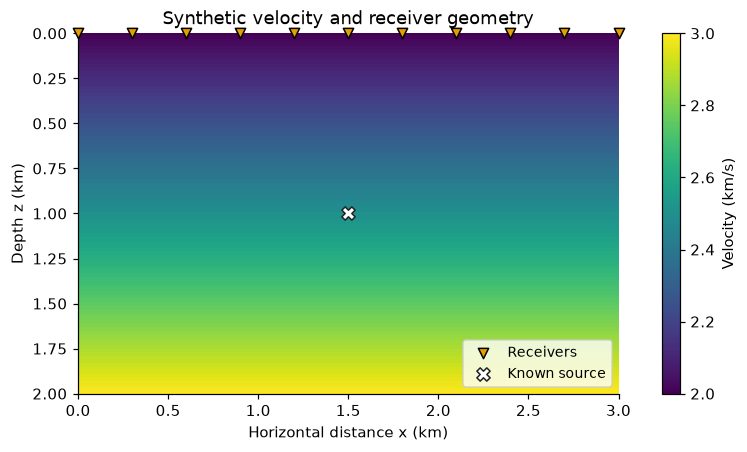

In [3]:
problem = prepare_problem(config)
streams = RandomStreams(config.seed, config.device)
initial_parameters = initialize_model(
    config.model.widths, config.model.initialization, streams,
    dtype=resolve_dtype(config.dtype), device=config.device,
)
forward = make_mlp_forward(config.model.activation)
batch = sample_training_batch(problem, config.data.collocation_count, streams)
z, x = as_numpy(problem.grid.z), as_numpy(problem.grid.x)
receivers = as_numpy(problem.receiver_coordinates)
truth = as_numpy(problem.true_source)
reference = as_numpy(problem.reference_times)
parameter_count = flatten_parameters(initial_parameters)[1].numel
print(f"{parameter_count:,} parameters; {len(z)} × {len(x)} grid; "
      f"{len(batch.coordinates)} fixed collocation points; {len(receivers)} receivers")
print(f"Grid spacing: dz={z[1]-z[0]:.3f} km, dx={x[1]-x[0]:.3f} km")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
mesh = ax.pcolormesh(x, z, as_numpy(problem.grid.velocity), shading="auto", cmap="viridis")
source_markers(ax)
spatial_axes(ax)
ax.set_title("Synthetic velocity and receiver geometry")
ax.legend(loc="lower right", fontsize=9)
fig.colorbar(mesh, ax=ax, label="Velocity (km/s)")
plt.show()
plt.close(fig)

### 2. Train the shared center

`train` returns new parameters and an optimizer/RNG snapshot. The input mapping remains unchanged. History records pre-update objectives; the final metrics below recompute the objective at the returned parameters.

In [4]:
started = time.perf_counter()
training = train(initial_parameters, batch, config.training, streams, forward=forward)
training_seconds = time.perf_counter() - started
parameters = training.parameters
center_field = predict_grid(parameters, problem.grid, config.prediction_chunk_size, forward=forward)
center_location = as_numpy(grid_location(center_field, problem.grid))
final_terms = loss_terms(parameters, batch, config.training, forward=forward)
field_rmse = float((center_field - problem.reference_times).square().mean().sqrt())
location_error = float(np.linalg.norm(center_location - truth))
with torch.no_grad():
    receiver_prediction = as_numpy(forward(parameters, problem.receiver_coordinates)).reshape(-1)
print(f"Training: {training_seconds:.2f} s; recomputed final objective: {float(final_terms.total.detach()):.3e}")
print(f"Field RMSE: {field_rmse:.5f} s; grid-minimum error: {location_error:.5f} km")
print(f"Trained minimum (z, x): {center_location.round(4)} km")

Training: 4.05 s; recomputed final objective: 5.503e-05
Field RMSE: 0.02246 s; grid-minimum error: 0.05657 km
Trained minimum (z, x): [1.04 1.54] km


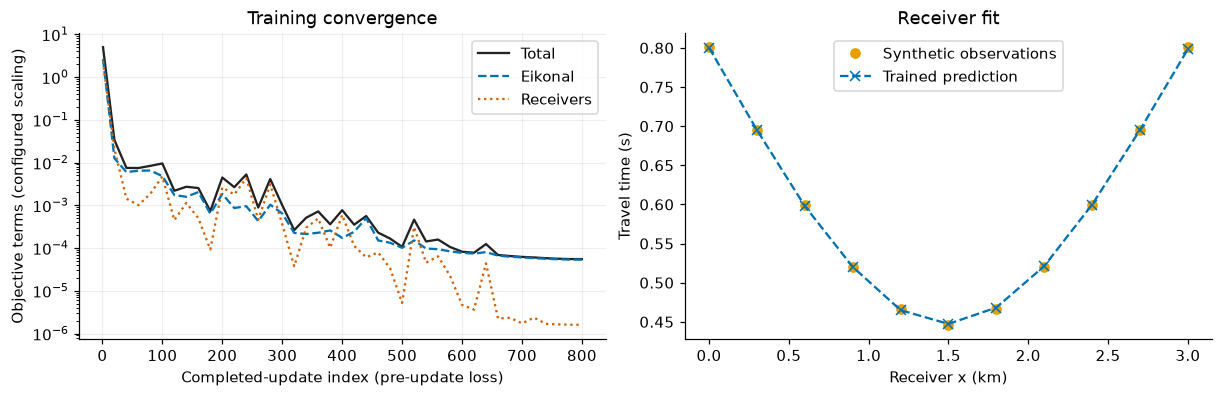

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
steps = [entry["step"] for entry in training.history]
for key, label, color, style in (
    ("total", "Total", "#222222", "-"),
    ("pde", "Eikonal", "#0072B2", "--"),
    ("data", "Receivers", "#D55E00", ":"),
):
    axes[0].semilogy(steps, [entry[key] for entry in training.history],
                     label=label, color=color, linestyle=style)
axes[0].set(xlabel="Completed-update index (pre-update loss)",
            ylabel="Objective terms (configured scaling)", title="Training convergence")
axes[0].legend()
axes[0].grid(alpha=.2)
axes[1].plot(receivers[:, 1], as_numpy(problem.receiver_times).reshape(-1),
             "o", color=colors["receiver"], label="Synthetic observations")
axes[1].plot(receivers[:, 1], receiver_prediction, "x--", color=colors["map"],
             label="Trained prediction")
axes[1].set(xlabel="Receiver x (km)", ylabel="Travel time (s)", title="Receiver fit")
axes[1].legend()
plt.show()
plt.close(fig)

Receiver agreement alone does not establish an accurate interior field. Compare the trained field with the analytic reference using one shared color scale, and inspect the signed error separately. A white X marks the known source; a blue star marks the trained grid minimum.

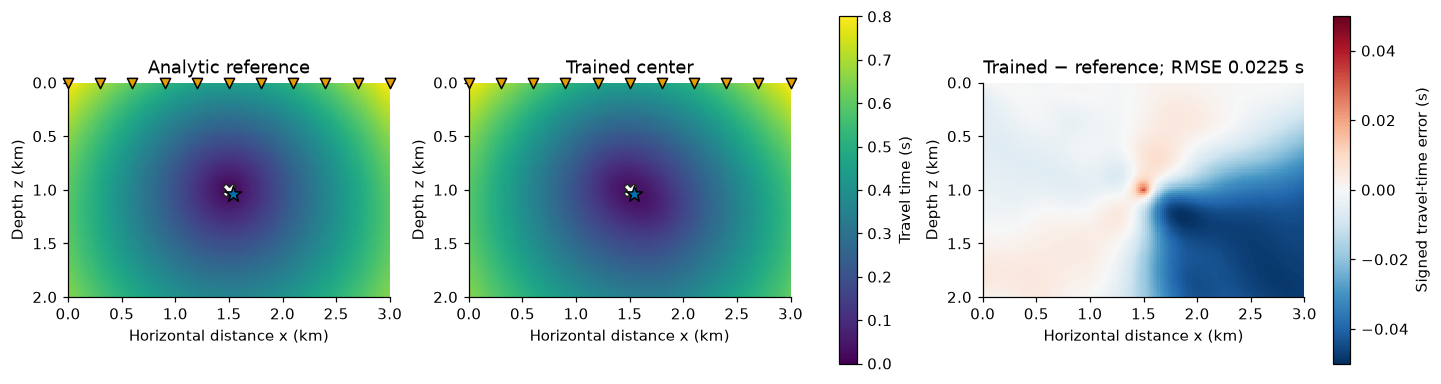

In [6]:
trained = as_numpy(center_field)
low, high = min(reference.min(), trained.min()), max(reference.max(), trained.max())
error = trained - reference
error_limit = max(float(np.abs(error).max()), np.finfo(float).eps)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, values, title in zip(axes[:2], (reference, trained),
                            ("Analytic reference", "Trained center"), strict=True):
    mesh = ax.pcolormesh(x, z, values, shading="auto", cmap="viridis", vmin=low, vmax=high)
    source_markers(ax, include_center=True)
    spatial_axes(ax)
    ax.set_title(title)
fig.colorbar(mesh, ax=axes[:2], label="Travel time (s)", shrink=.85)
mesh = axes[2].pcolormesh(x, z, error, shading="auto", cmap="RdBu_r",
                         vmin=-error_limit, vmax=error_limit)
spatial_axes(axes[2])
axes[2].set_title(f"Trained − reference; RMSE {field_rmse:.4f} s")
fig.colorbar(mesh, ax=axes[2], label="Signed travel-time error (s)", shrink=.85)
plt.show()
plt.close(fig)

### 3. Fit the selected curvature approximation

Corrected methods use a **fixed residual plan**, with global family weights applied before chunking. The legacy method instead resamples coordinates and squares the total loss gradient. The following cell calls the method’s public API directly; it does not execute archived notebook code.

In [7]:
from laplace_hypopinn.curvature.diagonal import fit_legacy_diagonal

plan = make_residual_plan(batch, config.training)
# Separate streams keep curvature selection independent of training and prediction.
streams = RandomStreams(config.seed + 1, config.device)
started = time.perf_counter()

# This method consumes the local NumPy stream to resample curvature batches.
# Re-run from the seed cell to replay the identical sequence.
posterior = fit_legacy_diagonal(
    parameters,
    problem,
    config.laplace,
    streams,
    forward=forward,
    training_config=config.training,
)
print(f"Representation: {posterior.representation}; parameters: {posterior.layout.numel:,}")
print(f"Curvature batches: {config.laplace.batches}; batch size: {config.laplace.batch_size}")
print(f"Post-hoc add: {config.laplace.add:g}; multiply: {config.laplace.multiply:g}")

fit_seconds = time.perf_counter() - started
print(f"Curvature fit: {fit_seconds:.2f} s; representation: {posterior.representation}")

Representation: diagonal; parameters: 2,737
Curvature batches: 64; batch size: 512
Post-hoc add: 1000; multiply: 0.001
Curvature fit: 0.27 s; representation: diagonal


### Inspect the method’s structure

Read the first plot as the distribution of the **unmodified batch-gradient-square statistic**. Positive values use logarithmic bins; the exact-zero count is stated separately, so no epsilon floor changes the statistic. Batch size and batch count affect this estimator, even when the trained parameters stay fixed.

The second plot shows exact marginal parameter standard deviations for this diagonal Gaussian; separators mark affine layers. Large `add` relative to `multiply*f` makes these standard deviations similar. This observation alone would not show that the model learned calibrated uncertainty. Compare subsequent travel-time fields and localization samples with the analytic reference, and assess training fit before interpreting spread. Nonlinear network evaluation can turn independent parameter perturbations into correlated spatial fields.


The parameter-SD axis starts at zero so numerical differences around a nearly constant value are not magnified. If the curve coincides with the damping-only line, the raw curvature statistic contributes little at the selected scaling; the printed ratio quantifies that effect.

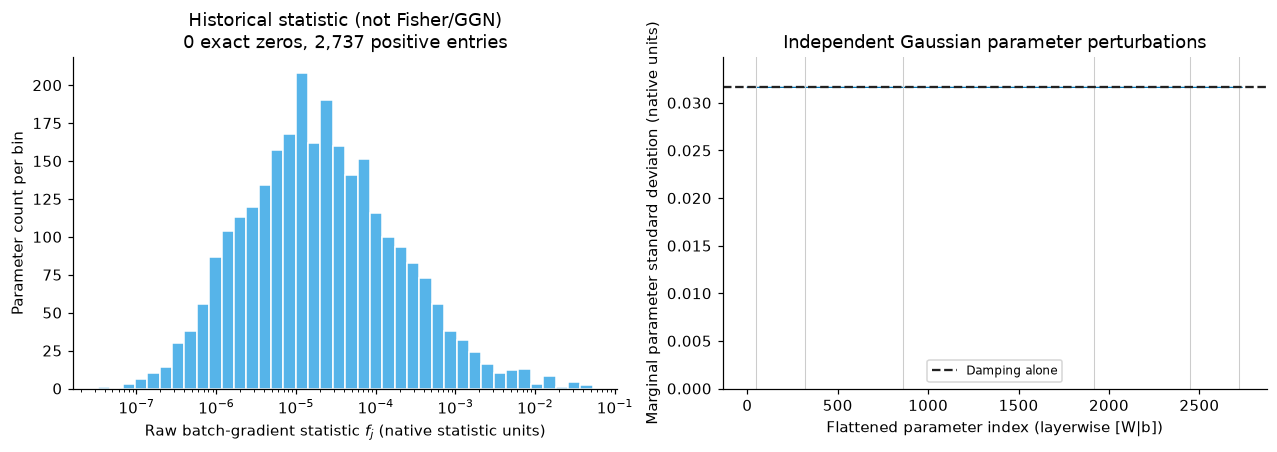

Raw statistic min / median / max: 3.2801e-08 / 1.8158e-05 / 0.05267
Marginal parameter SD min / max: 0.031623 / 0.031623
Stored precision: 0.010 MiB
Maximum raw curvature contribution / damping: 5.267e-08


In [8]:
# The raw statistic is retained separately: never relabel it as a Fisher/GGN.
raw = as_numpy(posterior.metadata["legacy_statistic"])
parameter_sd = as_numpy(posterior.diagonal.rsqrt())
positive = raw[raw > 0]
zero_count = int(np.count_nonzero(raw == 0))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), layout="constrained")
if positive.size:
    # Every positive entry is included; zeros are reported explicitly below.
    low, high = float(positive.min()), float(positive.max())
    if low < high:
        edges = np.geomspace(low, high, 41)
        edges[0], edges[-1] = low, high
    else:
        edges = np.array([low / 2, high * 2])
    axes[0].hist(positive, bins=edges, color=colors["posterior"], edgecolor="white")
    axes[0].set_xscale("log")
    axes[0].set_xlabel(r"Raw batch-gradient statistic $f_j$ (native statistic units)")
else:
    axes[0].bar([0], [zero_count], color=colors["posterior"])
    axes[0].set_xlabel(r"Raw batch-gradient statistic $f_j$ (native statistic units)")
axes[0].set_ylabel("Parameter count per bin")
axes[0].set_title(f"Historical statistic (not Fisher/GGN)\n{zero_count:,} exact zeros, {positive.size:,} positive entries")

axes[1].plot(np.arange(parameter_sd.size), parameter_sd, linewidth=0.8, color=colors["map"])
for block in posterior.layout.blocks[1:]:
    axes[1].axvline(block.start - 0.5, color="0.8", linewidth=0.7)
axes[1].set_xlabel("Flattened parameter index (layerwise [W|b])")
axes[1].set_ylabel("Marginal parameter standard deviation (native units)")
baseline_sd = config.laplace.add**-0.5
axes[1].axhline(baseline_sd, color=colors["truth"], linestyle="--", label="Damping alone")
axes[1].set_ylim(0, baseline_sd * 1.1)
axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
axes[1].legend(fontsize=8)
axes[1].set_title("Independent Gaussian parameter perturbations")
plt.show()
plt.close(fig)

print(f"Raw statistic min / median / max: {np.min(raw):.5g} / {np.median(raw):.5g} / {np.max(raw):.5g}")
print(f"Marginal parameter SD min / max: {parameter_sd.min():.5g} / {parameter_sd.max():.5g}")
print(f"Stored precision: {posterior.diagonal.numel() * posterior.diagonal.element_size() / 2**20:.3f} MiB")

print(f"Maximum raw curvature contribution / damping: {raw.max() * config.laplace.multiply / config.laplace.add:.3e}")

### 4. Sample complete fields and source locations

`sample_locations` keeps each parameter perturbation fixed across all grid chunks. It stores grid minima and online field moments instead of a sample-by-grid array. This method evaluates the **nonlinear model at each sampled parameter vector**. Every inferred source is a grid minimum; this finite grid limits localization resolution.

In [9]:
# A fresh explicit stream makes this cell reproducible when rerun.
prediction_streams = RandomStreams(config.seed + 2, config.device)
started = time.perf_counter()
summary = sample_locations(posterior, problem.grid, config, prediction_streams.torch)
prediction_seconds = time.perf_counter() - started
locations = as_numpy(summary.locations)
field_mean, field_std = as_numpy(summary.field_mean), as_numpy(summary.field_std)
print(f"Prediction convention: {posterior.prediction_kind}")
print(f"{len(locations)} coherent fields sampled in {prediction_seconds:.2f} s")
print(f"Source-location sample mean (z, x): {as_numpy(summary.mean).round(4)} km")
print(f"Source-location population SD (z, x): {as_numpy(summary.std).round(4)} km")

Prediction convention: travel_time
64 coherent fields sampled in 0.74 s
Source-location sample mean (z, x): [1.1131 1.5563] km
Source-location population SD (z, x): [0.2321 0.1667] km


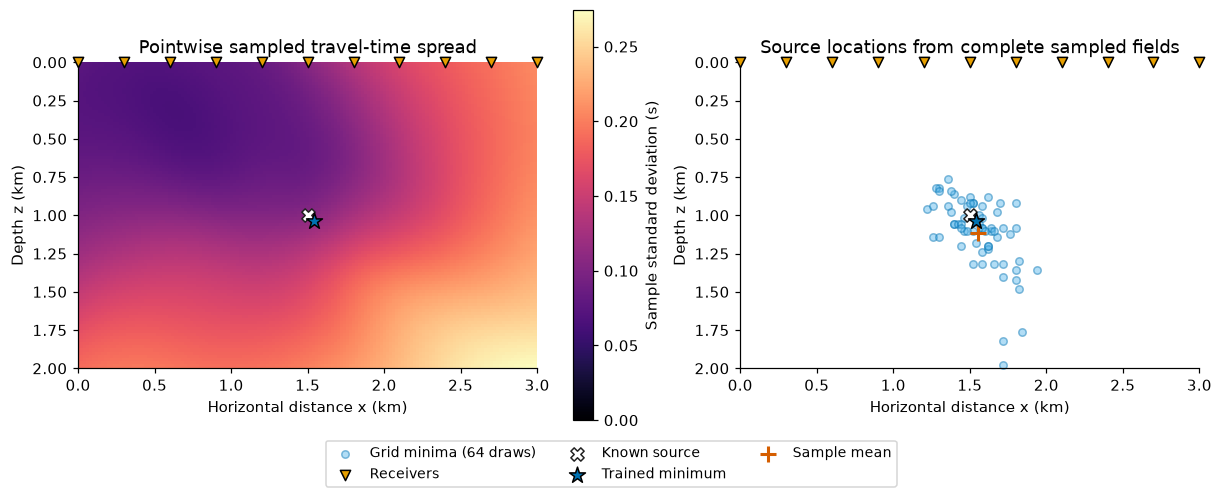

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
mesh = axes[0].pcolormesh(x, z, field_std, shading="auto", cmap="magma", vmin=0)
spatial_axes(axes[0])
source_markers(axes[0], include_center=True)
axes[0].set_title("Pointwise sampled travel-time spread")
fig.colorbar(mesh, ax=axes[0], label="Sample standard deviation (s)")
axes[1].scatter(locations[:, 1], locations[:, 0], s=24, alpha=.45,
                color=colors["posterior"], edgecolors=colors["map"], clip_on=False,
                label=f"Grid minima ({len(locations)} draws)")
source_markers(axes[1], include_center=True)
location_mean = as_numpy(summary.mean)
axes[1].scatter(location_mean[1], location_mean[0], marker="+", s=110,
                linewidths=2, color="#D55E00", label="Sample mean")
spatial_axes(axes[1])
axes[1].set_title("Source locations from complete sampled fields")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, fontsize=9)
plt.show()
plt.close(fig)

### Compare uncertainty with field error

The band below is the **sample mean ± two sample standard deviations at each grid point**. It is descriptive spread, **not a 95% credible interval or a simultaneous confidence band**. Negative sampled times are left visible; a Gaussian parameter approximation does not enforce physical positivity. Nonlinearity means the predictive mean can differ from the trained center.

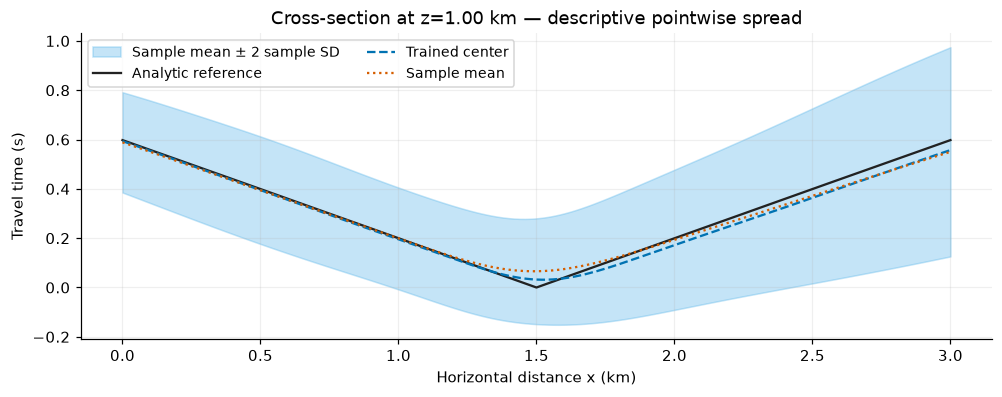

In [11]:
row = int(np.argmin(np.abs(z - truth[0])))
mean_row, std_row = field_mean[row], field_std[row]
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.fill_between(x, mean_row - 2*std_row, mean_row + 2*std_row,
                 color=colors["posterior"], alpha=.35, label="Sample mean ± 2 sample SD")
ax.plot(x, reference[row], color=colors["truth"], label="Analytic reference")
ax.plot(x, trained[row], "--", color=colors["map"], label="Trained center")
ax.plot(x, mean_row, ":", color="#D55E00", label="Sample mean")
ax.set(xlabel="Horizontal distance x (km)", ylabel="Travel time (s)",
        title=f"Cross-section at z={z[row]:.2f} km — descriptive pointwise spread")
ax.grid(alpha=.2)
ax.legend(ncol=2, fontsize=9)
plt.show()
plt.close(fig)

## Checks

These checks establish finite, internally consistent calculations. They do not test calibration, convergence to a global optimum, or agreement with a full research run.

In [12]:
center_vector, layout = flatten_parameters(parameters)
torch.testing.assert_close(posterior.mean, center_vector.detach(), rtol=0, atol=0)
assert summary.locations.shape == (config.laplace.samples, 2)
assert summary.field_mean.shape == summary.field_std.shape == problem.grid.shape
for value in (center_field, summary.locations, summary.field_mean, summary.field_std):
    assert torch.isfinite(value).all()
assert (summary.field_std >= 0).all()
assert np.isin(locations[:, 0], z).all() and np.isin(locations[:, 1], x).all()
for factor in (posterior.factor, *posterior.blocks):
    if factor is not None:
        assert torch.isfinite(factor).all() and (factor.diag() > 0).all()
if posterior.diagonal is not None:
    assert torch.isfinite(posterior.diagonal).all() and (posterior.diagonal > 0).all()
for _, _, precision in posterior.eigenbasis:
    assert torch.isfinite(precision).all() and (precision > 0).all()
print("Checks passed: finite fields, positive precision, preserved center, and grid-based samples.")
display(Markdown(
    f"**Observed in this run:** field RMSE **{field_rmse:.5f} s**, "
    f"trained grid-minimum error **{location_error:.5f} km**, and "
    f"**{len(locations)}** posterior draws. These are tutorial results; "
    "they do not establish uncertainty calibration or reproduce the paper's full experiments."
))

Checks passed: finite fields, positive precision, preserved center, and grid-based samples.


**Observed in this run:** field RMSE **0.02246 s**, trained grid-minimum error **0.05657 km**, and **64** posterior draws. These are tutorial results; they do not establish uncertainty calibration or reproduce the paper's full experiments.

## Next steps

- Hold the trained center fixed and vary `batches` and `batch_size` separately; record how the statistic and predictive spread change. Reset the local seed before each controlled comparison.
- Sweep `add` and `multiply` independently. Record both because only their joint action defines the sampled precision.
- Compare with the `diagonal` GGN notebook using the same trained center and explicit scales; the estimators do not have interchangeable meanings or normalization.
- Increase training and posterior sample counts, repeat seeds, and check empirical source-location coverage on multiple synthetic sources before making calibration claims.


- Change `config.model.widths` or `activation`, then restart and rerun training and curvature. For a custom pointwise model, see the [extension example](../extend_research.py) and [model contract](../../docs/architecture.md). Structured methods need a compatible jet adapter.
- For saved configurations, checkpoints, result arrays and standard plots, use the orchestration API with a **new output directory**:

```python
from laplace_hypopinn.experiment import run_experiment
result = run_experiment(config, output="results/legacy_diagonal-new-run")
```

This starts a new experiment with its own seed schedule; it is not a serializer for the manually computed objects above. Use the [reproducibility guide](../../docs/reproducibility.md) and [measured performance](../../docs/performance.md) before increasing research budgets.